# Phase 1: CT Preprocessing & Spatial/Frequency Enhancement

**Goal:** convert raw attenuation values (HU) into an optimised soft-tissue grayscale image and reduce noise, then quantify the effect with PSNR and CNR.

| Task | What is done here |
|---|---|
| 1 | HU windowing, clipping and normalisation to 0-255 |
| 2 | Spatial filtering (Gaussian, median, bilateral, anisotropic diffusion) and contrast enhancement (HE vs CLAHE) |
| 3 | 2D-DFT log-magnitude spectrum, Butterworth low-pass and homomorphic filtering |
| 4 | Validation with PSNR and CNR, averaged over many slices |

All functions live in `../source/utilities.py` and `../source/enhancement.py`; this notebook only calls them and shows the results.

In [1]:
import sys, os
sys.path.append("../source")          # the modules live in ../source
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import utilities as util
import enhancement as enh

DATA_DIR = "../data/slices"           # extracted .npz slices (patient_<N>.npz)
FIG_DIR = "../figures"                # figures for the report are saved here
os.makedirs(FIG_DIR, exist_ok=True)
plt.rcParams["figure.dpi"] = 90
plt.rcParams["figure.max_open_warning"] = 0

## Task 1: Image enhancement & intensity normalisation

A CT slice stores Hounsfield Units (HU): water = 0, air = -1000, bone > +300. Soft tissue occupies only a narrow band, so the full range wastes almost all gray levels. **Windowing** clips HU to `[level - width/2, level + width/2]` and the clipped values are mapped linearly to 0-255:

$$I' = 255 \cdot \frac{I - lo}{hi - lo}$$

In [2]:
PID, POS = 3, 4                                  # patient 3, 5th stored slice (contains a tumor)
hu_all, mask_all, idx = util.load_patient(DATA_DIR, PID)
hu, mask = hu_all[POS], mask_all[POS]
print("patient", PID, "| original slice no.", idx[POS], "| shape", hu.shape)
print("HU range: %.0f .. %.0f" % (hu.min(), hu.max()))
print("liver pixels (incl. tumor): %d | tumor pixels: %d" % ((mask >= 1).sum(), (mask == 2).sum()))
print("patients available:", util.list_patients(DATA_DIR))

patient 3 | original slice no. 364 | shape (512, 512)
HU range: -1024 .. 1477
liver pixels (incl. tumor): 12350 | tumor pixels: 254
patients available: [0, 1, 2, 3, 4, 5, 6, 7, 8, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]


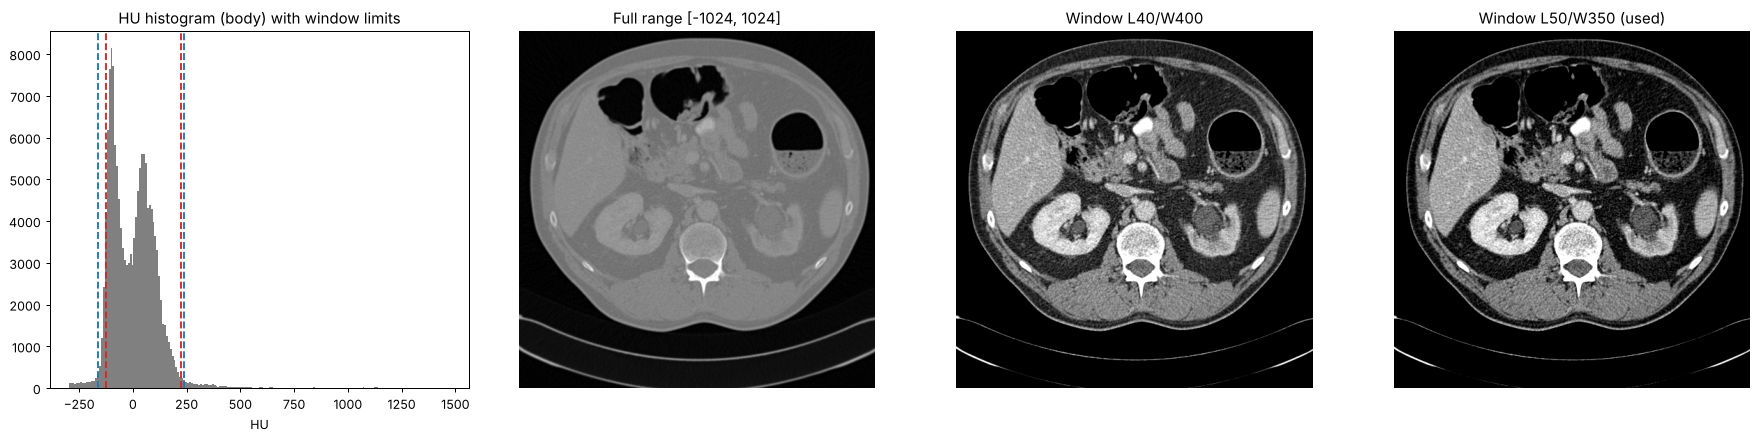

In [ ]:
# Raw HU vs. two soft-tissue windows
raw_gray = util.normalize_0_255(np.clip(hu, -1024, 1024), -1024, 1024)       # no windowing (full range)
wide = util.hu_to_gray(hu, *util.WIDE_WINDOW)                                 # level 40 / width 400
liver = util.hu_to_gray(hu, *util.LIVER_WINDOW)                               # level 50 / width 350

fig, ax = plt.subplots(1, 4, figsize=(20, 5))
ax[0].hist(hu[hu > -300].ravel(), 200, color="gray")
for lo, hi, c in [(-160, 240, "tab:blue"), (-125, 225, "tab:red")]:
    ax[0].axvline(lo, color=c, ls="--"); ax[0].axvline(hi, color=c, ls="--")
ax[0].set_title("HU histogram (body) with window limits"); ax[0].set_xlabel("HU")
for a, im, t in zip(ax[1:], [raw_gray, wide, liver], ["Full range [-1024, 1024]", "Window L40/W400", "Window L50/W350 (used)"]):
    a.imshow(im, cmap="gray", vmin=0, vmax=255); a.set_title(t); a.axis("off")
fig.tight_layout(); fig.savefig(FIG_DIR + "/p1_windowing.png", dpi=110); plt.show()

In [4]:
# How much of the gray range does each window give to liver tissue vs. to the tumor?
liver_px = mask == 1; tumor_px = mask == 2
rows = []
for name, im in [("Full range", raw_gray), ("L40/W400", wide), ("L50/W350", liver)]:
    rows.append((name, im[liver_px].mean(), im[tumor_px].mean(), abs(im[liver_px].mean() - im[tumor_px].mean()), im[liver_px].std()))
pd.DataFrame(rows, columns=["window", "mean gray liver", "mean gray tumor", "difference", "std liver"]).round(1)

,window,mean gray liver,mean gray tumor,difference,std liver
0,Full range,140.2,136.7,3.5,3.2
1,L40/W400,167.1,149.4,17.8,16.2
2,L50/W350,165.5,145.2,20.3,18.5


**Findings (windowing).** On this slice the mean gray difference between liver and tumor is only 3.5 levels with the full HU range, but 17.8 with L40/W400 and 20.3 with L50/W350, roughly a 6x increase in separation. The narrower L50/W350 window gives the largest difference and is used in all later phases.

## Task 2: Spatial-domain filtering

CT noise (and streaking) is attenuated with four filters. The window is the same for all, so differences come from the filter only.

* **Gaussian** - isotropic blur, blurs edges as much as noise.
* **Median** - non-linear, removes impulse-like noise, keeps edges moderately.
* **Bilateral** - weights neighbours by distance *and* intensity similarity, so it does not average across edges.
* **Anisotropic diffusion (Perona-Malik)** - diffusion that stops where the gradient is large: $c(\lVert\nabla I\rVert) = 1/(1 + (\lVert\nabla I\rVert/\kappa)^2)$.

A CT slice has no noise-free version, so **PSNR** is measured against a *reference*: the windowed slice itself, to which Gaussian noise (σ = 12 gray levels) is added. Filters are scored on how well they recover the reference. **CNR** (liver vs. surrounding tissue ring, and parenchyma vs. tumor) measures separability, and an **edge strength** measure (mean Sobel gradient along the liver boundary) shows how much edge detail survives.

In [5]:
SIGMA = 12
clean = liver                                         # reference: windowed slice
noisy = enh.add_gaussian_noise(clean, sigma=SIGMA, seed=0)

liver_all = mask >= 1
parenchyma = mask == 1
tumor_roi = mask == 2
ring = enh.surrounding_ring(liver_all) & enh.body_mask(hu)

def edge_strength(img, region):
    """Mean Sobel gradient magnitude along the boundary of `region` (higher = sharper edge kept)."""
    g = np.hypot(cv2.Sobel(img.astype(np.float32), cv2.CV_32F, 1, 0), cv2.Sobel(img.astype(np.float32), cv2.CV_32F, 0, 1))
    b = cv2.morphologyEx(region.astype(np.uint8), cv2.MORPH_GRADIENT, np.ones((3, 3), np.uint8)) > 0
    return float(g[b].mean())

filtered = {
    "Noisy input": noisy,
    "Gaussian (s=1.5)": enh.gaussian_smooth(noisy, 1.5),
    "Median (5x5)": enh.median_smooth(noisy, 5),
    "Bilateral": enh.bilateral_smooth(noisy),
    "Anisotropic (15 it)": enh.anisotropic_diffusion(noisy),
}
rows = [(n, enh.psnr(clean, im), enh.cnr(im, liver_all, ring), enh.cnr(im, parenchyma, tumor_roi), edge_strength(im, liver_all))
        for n, im in filtered.items()]
tbl_filters = pd.DataFrame(rows, columns=["method", "PSNR (dB)", "CNR liver/ring", "CNR liver/tumor", "edge strength"]).set_index("method").round(2)
tbl_filters

,PSNR (dB),CNR liver/ring,CNR liver/tumor,edge strength
method,,,,
Noisy input,27.82,1.27,0.73,261.73
Gaussian (s=1.5),23.99,1.46,1.40,164.49
Median (5x5),24.27,1.40,1.50,199.80
Bilateral,27.50,1.41,1.56,219.23
Anisotropic (15 it),26.34,1.43,1.63,204.34


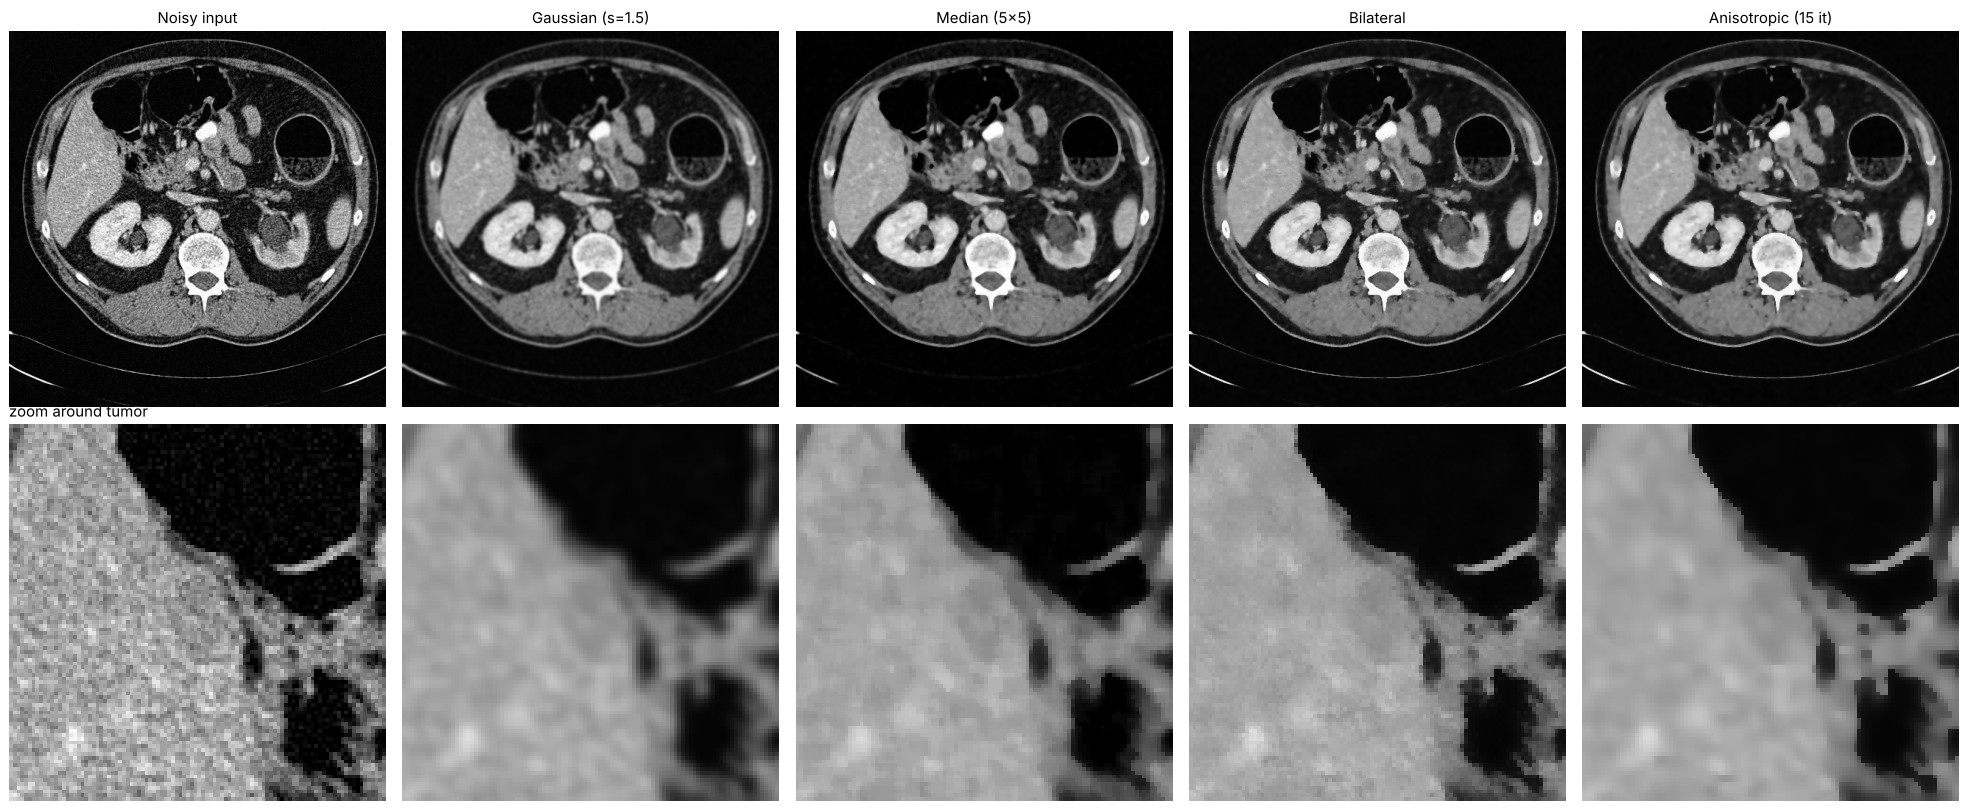

In [6]:
# Whole slice + zoom on the liver boundary / tumor region
ys, xs = np.where(tumor_roi)
cy, cx = int(ys.mean()), int(xs.mean())
y0, x0 = max(cy - 50, 0), max(cx - 50, 0)
fig, ax = plt.subplots(2, 5, figsize=(22, 9))
for j, (n, im) in enumerate(filtered.items()):
    ax[0, j].imshow(im, cmap="gray", vmin=0, vmax=255); ax[0, j].set_title(n); ax[0, j].axis("off")
    ax[1, j].imshow(im[y0:y0 + 100, x0:x0 + 100], cmap="gray", vmin=0, vmax=255, interpolation="nearest"); ax[1, j].axis("off")
ax[1, 0].set_title("zoom around tumor", loc="left")
fig.tight_layout(); fig.savefig(FIG_DIR + "/p1_denoising.png", dpi=100); plt.show()

### Contrast enhancement: Histogram Equalisation vs CLAHE

* **HE** remaps gray levels through the cumulative histogram of the *whole* image. It can over-stretch and amplifies noise.
* **CLAHE** does this in small tiles and clips each tile's histogram (`clip_limit`) before equalising, which limits noise amplification.

Both are applied to the bilateral-filtered image (the edge-preserving filter), so noise is not amplified twice.

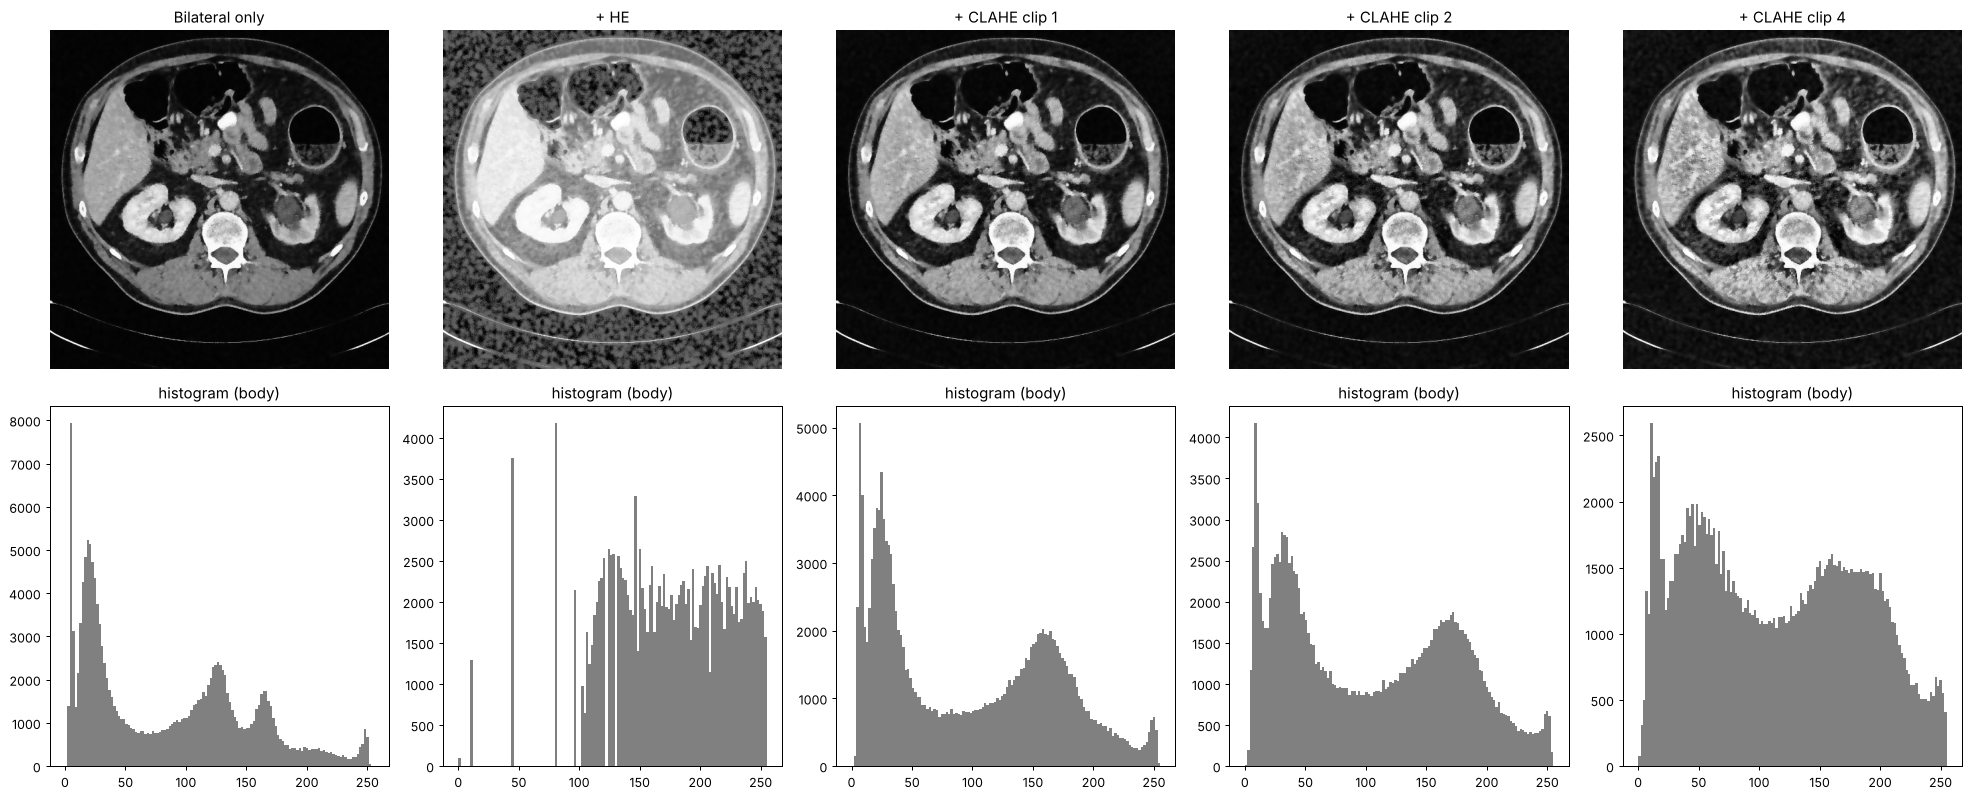

,CNR liver/ring,CNR liver/tumor,edge strength
method,,,
Bilateral only,1.41,1.56,219.23
+ HE,1.33,1.50,150.14
+ CLAHE clip 1,1.28,0.74,232.03
+ CLAHE clip 2,1.23,0.70,227.13
+ CLAHE clip 4,1.12,0.77,210.94


In [7]:
base = filtered["Bilateral"]
variants = {
    "Bilateral only": base,
    "+ HE": enh.histogram_equalize(base),
    "+ CLAHE clip 1": enh.clahe_equalize(base, 1.0, (8, 8)),
    "+ CLAHE clip 2": enh.clahe_equalize(base, 2.0, (8, 8)),
    "+ CLAHE clip 4": enh.clahe_equalize(base, 4.0, (8, 8)),
}
fig, ax = plt.subplots(2, 5, figsize=(22, 9))
for j, (n, im) in enumerate(variants.items()):
    ax[0, j].imshow(im, cmap="gray", vmin=0, vmax=255); ax[0, j].set_title(n); ax[0, j].axis("off")
    ax[1, j].hist(im[enh.body_mask(hu)].ravel(), 128, range=(0, 255), color="gray"); ax[1, j].set_title("histogram (body)")
fig.tight_layout(); fig.savefig(FIG_DIR + "/p1_hist_eq.png", dpi=100); plt.show()

rows = [(n, enh.cnr(im, liver_all, ring), enh.cnr(im, parenchyma, tumor_roi), edge_strength(im, liver_all)) for n, im in variants.items()]
pd.DataFrame(rows, columns=["method", "CNR liver/ring", "CNR liver/tumor", "edge strength"]).set_index("method").round(2)

## Task 3: Frequency-domain enhancement

The 2D-DFT $F(u,v)$ of the slice is shifted so low frequencies sit in the centre; the log-magnitude spectrum $\log(1+|F|)$ makes it visible. Noise adds energy at high radii.

**Butterworth low-pass** $H(u,v) = \dfrac{1}{1 + [D(u,v)/D_0]^{2n}}$ attenuates frequencies beyond the cut-off $D_0$ smoothly (no ringing of an ideal filter).

**Homomorphic filter**: $\ln I = \ln(\text{illumination}) + \ln(\text{reflectance})$. A high-emphasis filter in the log domain suppresses the slowly varying illumination ($\gamma_L<1$) and boosts detail ($\gamma_H>1$).

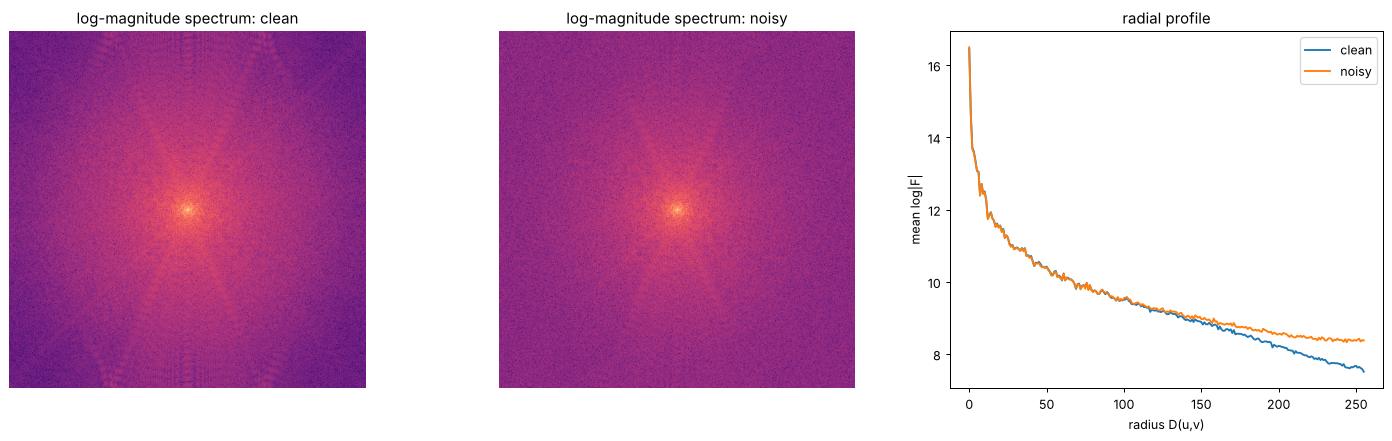

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
ax[0].imshow(enh.log_magnitude_spectrum(clean), cmap="magma"); ax[0].set_title("log-magnitude spectrum: clean")
ax[1].imshow(enh.log_magnitude_spectrum(noisy), cmap="magma"); ax[1].set_title("log-magnitude spectrum: noisy")
# radially averaged spectrum shows where the noise adds energy
def radial(img):
    s = enh.log_magnitude_spectrum(img); D = enh._dist_grid(img.shape).astype(int)
    return np.bincount(D.ravel(), s.ravel()) / np.maximum(np.bincount(D.ravel()), 1)
r_clean, r_noisy = radial(clean), radial(noisy)
ax[2].plot(r_clean[:256], label="clean"); ax[2].plot(r_noisy[:256], label="noisy"); ax[2].legend()
ax[2].set_xlabel("radius D(u,v)"); ax[2].set_ylabel("mean log|F|"); ax[2].set_title("radial profile")
for a in ax[:2]: a.axis("off")
fig.tight_layout(); fig.savefig(FIG_DIR + "/p1_spectrum.png", dpi=100); plt.show()

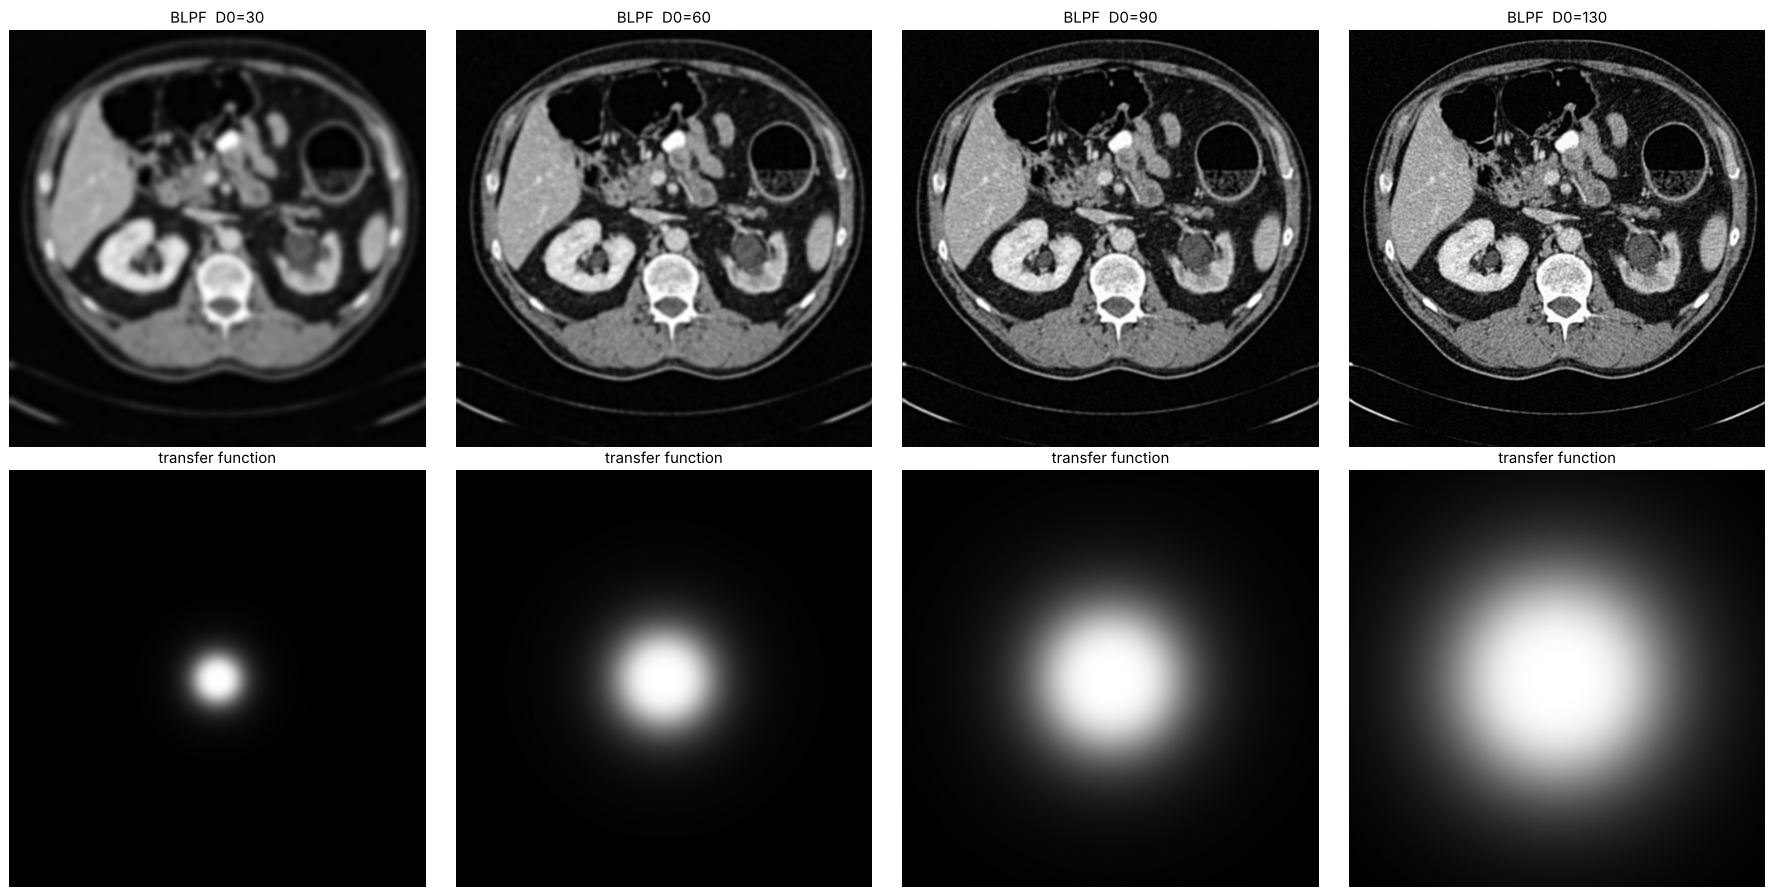

,PSNR (dB),CNR liver/ring,CNR liver/tumor,edge strength
method,,,,
BLPF D0=30,20.69,1.56,1.03,97.26
BLPF D0=60,23.72,1.44,1.42,165.30
BLPF D0=90,26.11,1.39,1.30,205.04
BLPF D0=130,28.59,1.35,1.09,232.74


In [9]:
# Butterworth low-pass for several cut-offs (order 2)
d0s = [30, 60, 90, 130]
fig, ax = plt.subplots(2, 4, figsize=(20, 10))
rows = []
for j, d0 in enumerate(d0s):
    out, H = enh.butterworth_lowpass(noisy, d0=d0, order=2)
    ax[0, j].imshow(out, cmap="gray", vmin=0, vmax=255); ax[0, j].set_title("BLPF  D0=%d" % d0); ax[0, j].axis("off")
    ax[1, j].imshow(H, cmap="gray"); ax[1, j].set_title("transfer function"); ax[1, j].axis("off")
    rows.append(("BLPF D0=%d" % d0, enh.psnr(clean, out), enh.cnr(out, liver_all, ring), enh.cnr(out, parenchyma, tumor_roi), edge_strength(out, liver_all)))
fig.tight_layout(); fig.savefig(FIG_DIR + "/p1_blpf.png", dpi=100); plt.show()
pd.DataFrame(rows, columns=["method", "PSNR (dB)", "CNR liver/ring", "CNR liver/tumor", "edge strength"]).set_index("method").round(2)

`enhancement.homomorphic` rescales its output with a plain min-max normalisation. The exponential step creates a few extremely bright pixels (bone, table edge), so min-max squeezes all soft tissue into a few dark gray levels (second column below). The notebook therefore also shows a **robust variant** that rescales with the 1st-99.5th percentile of the body instead (second row). This is a recommended one-line change to `homomorphic` in `enhancement.py`.

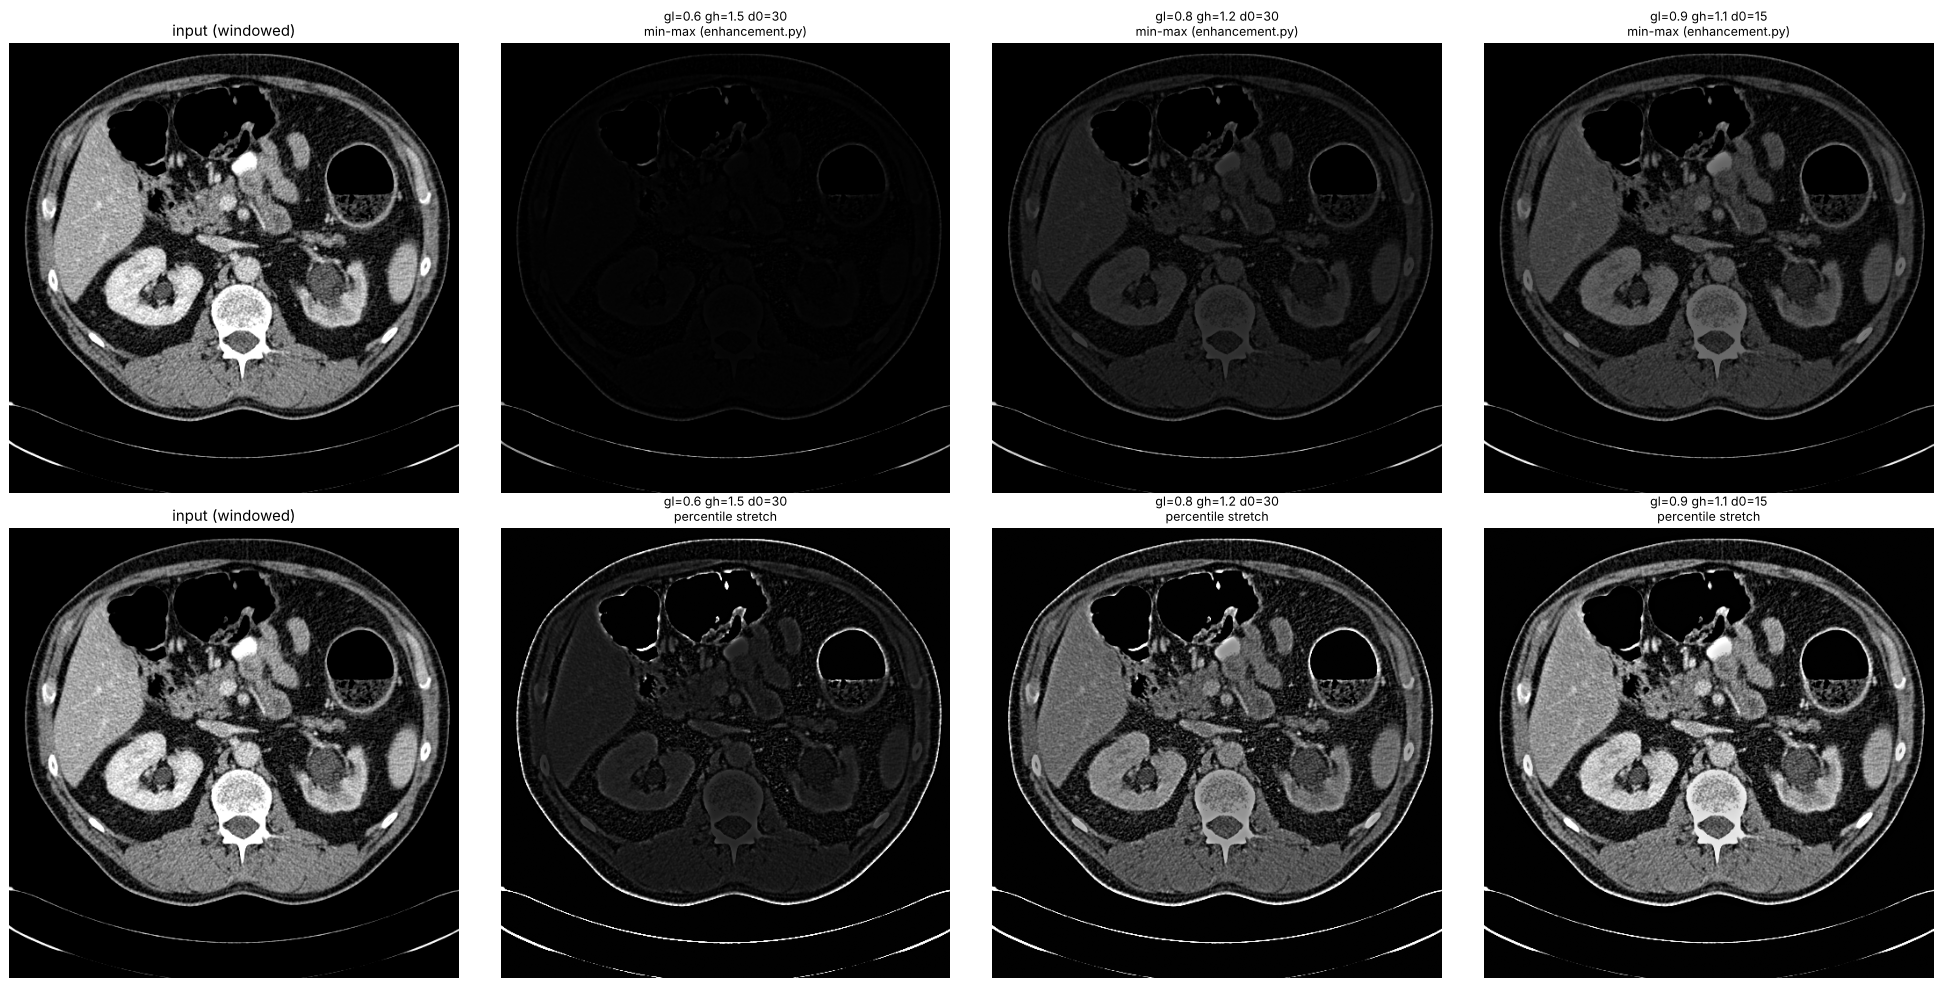

,parameters,rescaling,CNR liver/ring,CNR liver/tumor,edge strength
0,input,-,1.29,0.84,259.68
1,gl=0.6 gh=1.5 d0=30,min-max (enhancement.py),0.31,0.38,11.34
2,gl=0.6 gh=1.5 d0=30,percentile stretch,0.36,0.37,85.40
3,gl=0.8 gh=1.2 d0=30,min-max (enhancement.py),0.91,0.63,64.57
4,gl=0.8 gh=1.2 d0=30,percentile stretch,0.92,0.63,212.11
5,gl=0.9 gh=1.1 d0=15,min-max (enhancement.py),1.05,0.58,122.06
6,gl=0.9 gh=1.1 d0=15,percentile stretch,1.05,0.58,268.13


In [10]:
body_s = enh.body_mask(hu)

def homomorphic_robust(img, body, d0=30, gamma_l=0.6, gamma_h=1.5, c=1.0, p=(1, 99.5)):
    """Same filter as enh.homomorphic, but rescaled with percentiles of the body so outliers do not dominate."""
    f = np.log1p(img.astype(np.float64))
    D = enh._dist_grid(img.shape)
    H = (gamma_h - gamma_l) * (1 - np.exp(-c * D ** 2 / d0 ** 2)) + gamma_l
    out = np.expm1(np.real(np.fft.ifft2(np.fft.ifftshift(enh.dft2(f) * H))))
    lo, hi = np.percentile(out[body], p)
    return util.normalize_0_255(np.clip(out, lo, hi), lo, hi)

settings = {"gl=0.6 gh=1.5 d0=30": dict(d0=30, gamma_l=0.6, gamma_h=1.5),
            "gl=0.8 gh=1.2 d0=30": dict(d0=30, gamma_l=0.8, gamma_h=1.2),
            "gl=0.9 gh=1.1 d0=15": dict(d0=15, gamma_l=0.9, gamma_h=1.1)}
fig, ax = plt.subplots(2, 4, figsize=(22, 11))
for r in range(2):
    ax[r, 0].imshow(clean, cmap="gray", vmin=0, vmax=255); ax[r, 0].set_title("input (windowed)"); ax[r, 0].axis("off")
rows = [("input", "-", enh.cnr(clean, liver_all, ring), enh.cnr(clean, parenchyma, tumor_roi), edge_strength(clean, liver_all))]
for j, (n, p) in enumerate(settings.items(), start=1):
    out_mm, _ = enh.homomorphic(clean, **p)
    out_rb = homomorphic_robust(clean, body_s, **p)
    for r, (out, tag) in enumerate([(out_mm, "min-max (enhancement.py)"), (out_rb, "percentile stretch")]):
        ax[r, j].imshow(out, cmap="gray", vmin=0, vmax=255); ax[r, j].set_title(n + "\n" + tag, fontsize=10); ax[r, j].axis("off")
        rows.append((n, tag, enh.cnr(out, liver_all, ring), enh.cnr(out, parenchyma, tumor_roi), edge_strength(out, liver_all)))
fig.tight_layout(); fig.savefig(FIG_DIR + "/p1_homomorphic.png", dpi=100); plt.show()
pd.DataFrame(rows, columns=["parameters", "rescaling", "CNR liver/ring", "CNR liver/tumor", "edge strength"]).round(2)

## Task 4: Validation over many slices

One slice is an anecdote, so the methods are scored on **every tumor-bearing slice of the training patients** (the test patients are never used for choosing methods). Metrics are reported as mean ± standard deviation.

*PSNR is only meaningful for the denoisers: HE, CLAHE and homomorphic filtering change contrast on purpose, so they are judged by CNR only.*

In [11]:
train_p, test_p = util.split_patients(util.list_patients(DATA_DIR))
print("training patients:", train_p)
print("test patients (not used here):", test_p)

records = []
for pid, sl, hu_i, m_i in util.iter_slices(DATA_DIR, train_p):
    if (m_i >= 1).sum() < 3000 or (m_i == 2).sum() < 50:
        continue                                         # need liver and a visible tumor for both CNRs
    cl = util.hu_to_gray(hu_i)
    ny = enh.add_gaussian_noise(cl, sigma=SIGMA, seed=int(pid * 1000 + sl))
    lv, pa, tu = m_i >= 1, m_i == 1, m_i == 2
    rg = enh.surrounding_ring(lv) & enh.body_mask(hu_i)
    bil = enh.bilateral_smooth(ny)
    methods = {
        "Noisy input": ny,
        "Gaussian": enh.gaussian_smooth(ny, 1.5),
        "Median": enh.median_smooth(ny, 5),
        "Bilateral": bil,
        "Anisotropic": enh.anisotropic_diffusion(ny),
        "BLPF (D0=60)": enh.butterworth_lowpass(ny, 60, 2)[0],
        "Bilateral + HE": enh.histogram_equalize(bil),
        "Bilateral + CLAHE": enh.clahe_equalize(bil, 2.0, (8, 8)),
        "Homomorphic (min-max)": enh.homomorphic(cl)[0],
        "Homomorphic (percentile)": homomorphic_robust(cl, enh.body_mask(hu_i), d0=30, gamma_l=0.8, gamma_h=1.2),
    }
    for n, im in methods.items():
        records.append(dict(patient=pid, slice=sl, method=n,
                            psnr=enh.psnr(cl, im) if n in ("Noisy input", "Gaussian", "Median", "Bilateral", "Anisotropic", "BLPF (D0=60)") else np.nan,
                            cnr_ring=enh.cnr(im, lv, rg), cnr_tumor=enh.cnr(im, pa, tu), edge=edge_strength(im, lv)))
df = pd.DataFrame(records)
print("slices evaluated:", df.groupby("method").size().iloc[0])

training patients: [0, 1, 2, 3, 4, 6, 8, 10, 11, 12, 13, 14, 15, 16, 18, 19, 20, 21, 24, 28, 29]
test patients (not used here): [5, 7, 17, 22, 23, 25, 26, 27, 30]


slices evaluated: 121


In [12]:
order = ["Noisy input", "Gaussian", "Median", "Bilateral", "Anisotropic", "BLPF (D0=60)", "Bilateral + HE", "Bilateral + CLAHE", "Homomorphic (min-max)", "Homomorphic (percentile)"]
g = df.groupby("method")[["psnr", "cnr_ring", "cnr_tumor", "edge"]].agg(["mean", "std"]).loc[order]
fmt = lambda m, s: ("%.2f ± %.2f" % (m, s)) if not np.isnan(m) else "n/a"
summary = pd.DataFrame({
    "PSNR (dB)": [fmt(g.loc[n, ("psnr", "mean")], g.loc[n, ("psnr", "std")]) for n in order],
    "CNR liver/ring": [fmt(g.loc[n, ("cnr_ring", "mean")], g.loc[n, ("cnr_ring", "std")]) for n in order],
    "CNR liver/tumor": [fmt(g.loc[n, ("cnr_tumor", "mean")], g.loc[n, ("cnr_tumor", "std")]) for n in order],
    "edge strength": [fmt(g.loc[n, ("edge", "mean")], g.loc[n, ("edge", "std")]) for n in order],
}, index=order)
summary.to_csv(FIG_DIR + "/p1_validation_table.csv")
summary

,PSNR (dB),CNR liver/ring,CNR liver/tumor,edge strength
Noisy input,28.11 ± 0.28,1.07 ± 0.35,0.67 ± 0.31,205.12 ± 41.39
Gaussian,24.63 ± 1.17,1.24 ± 0.40,1.22 ± 0.57,123.09 ± 29.21
Median,25.19 ± 1.36,1.19 ± 0.40,1.22 ± 0.56,143.13 ± 39.19
Bilateral,28.66 ± 1.14,1.18 ± 0.40,1.20 ± 0.54,155.52 ± 45.29
Anisotropic,27.47 ± 1.40,1.20 ± 0.40,1.30 ± 0.60,145.30 ± 42.63
BLPF (D0=60),24.42 ± 1.18,1.22 ± 0.40,1.25 ± 0.57,124.42 ± 29.82
Bilateral + HE,n/a,1.17 ± 0.26,1.25 ± 0.53,89.33 ± 28.92
Bilateral + CLAHE,n/a,1.05 ± 0.36,1.14 ± 0.66,181.21 ± 43.04
Homomorphic (min-max),n/a,0.29 ± 0.24,0.47 ± 0.21,9.26 ± 3.95
Homomorphic (percentile),n/a,0.78 ± 0.37,0.70 ± 0.31,174.82 ± 44.97


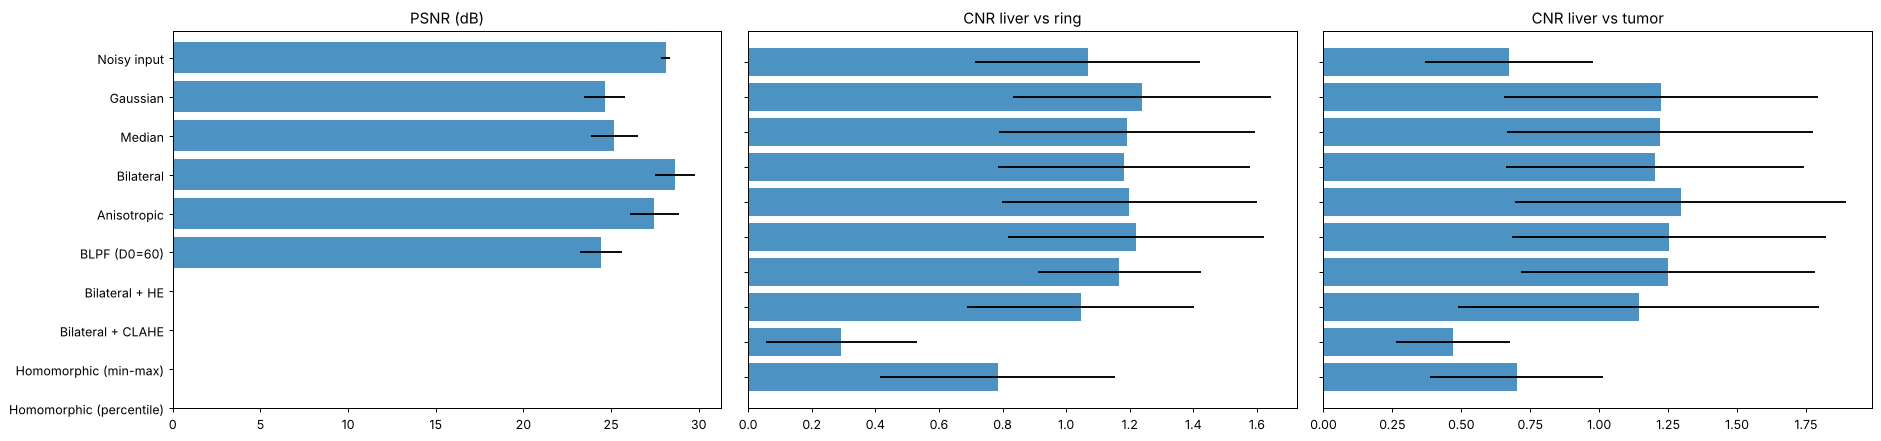

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(21, 5))
for a, col, t in zip(ax, ["psnr", "cnr_ring", "cnr_tumor"], ["PSNR (dB)", "CNR liver vs ring", "CNR liver vs tumor"]):
    m = df.groupby("method")[col].mean().loc[order]; s = df.groupby("method")[col].std().loc[order]
    a.barh(range(len(order)), m.values, xerr=s.values, color="tab:blue", alpha=.8); a.set_yticks(range(len(order)))
    a.set_yticklabels(order if col == "psnr" else [""] * len(order)); a.invert_yaxis(); a.set_title(t)
fig.tight_layout(); fig.savefig(FIG_DIR + "/p1_validation_bars.png", dpi=100); plt.show()

**Findings (121 tumor-bearing training slices).**

* **Denoising:** every filter roughly doubles the liver/tumor CNR compared with the noisy input (0.67 -> 1.20-1.30), and the differences between filters are smaller than their standard deviations (about 0.55). The filters differ mainly in what they do to edges and PSNR. Gaussian (24.6 dB) and median (25.2 dB) fall *below* the noisy input (28.1 dB) because they blur real edges as well as noise. **Bilateral is the only one that exceeds the noisy input (28.7 dB)** and keeps the most edge strength (155, vs 123 Gaussian, 143 median, 145 anisotropic). Anisotropic diffusion has the highest liver/tumor CNR (1.30) but a lower PSNR (27.5 dB). PSNR of the noisy input is partly inflated because noise added to saturated pixels (0 and 255) is clipped away.
* **HE vs CLAHE:** global HE keeps the CNR (1.25 liver/tumor) but compresses the liver's gray range and cuts edge strength to 89. CLAHE lowers CNR (1.05 liver/ring, 1.14 liver/tumor) while raising the edge-strength number (181), which is the signature of amplified noise rather than real detail. Neither improves separability, so neither is used before segmentation.
* **Butterworth low-pass (D0 = 60):** CNR is as good as the spatial filters (1.22 / 1.25), but, like the Gaussian, it blurs edges (PSNR 24.4 dB, edge strength 124): an isotropic low-pass cannot distinguish noise from boundaries.
* **Homomorphic filtering:** with the default `min-max` rescaling the output collapses (CNR 0.29 / 0.47, edge strength 9) because a few extreme pixels dominate the scaling. A percentile-based rescaling restores the contrast (edge strength 175) but CNR (0.78 / 0.70) is still below that of the unfiltered slice (1.29 / 0.84 on the example slice). A windowed soft-tissue slice has no strong illumination gradient to correct, so the filter has little to offer here.

**Conclusion:** window L50/W350 followed by the **bilateral filter** is the best trade-off between noise reduction and edge preservation, and is used as the front end of Phase 2.

## Decision carried into Phase 2

The segmentation code uses the **liver window (L50/W350)** followed by the **bilateral filter** (`segmentation.smooth_for_segmentation`). CLAHE is kept as an optional step for visual display; see the findings above for why.